# When New Yorkers report noise, hour by hour

Every noise complaint made to New York City's 311 in 2025, after cleaning, turned into an average week: how many reports
come in each of its 168 hours, Monday 00:00 to Sunday 23:00. The hexagons in `data/geometry/` were made in
[Plotlay](https://www.getplotlay.com). The notebook reads only `../data`.

311 counts people who chose to report. It shows who reports noise and when, not how loud the city is.

In [1]:
import json, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt, numpy as np
DATA = '../data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
r = pd.read_csv(f'{DATA}/reports/noise_reports_2025.csv.gz')
cleaning = json.load(open(f'{DATA}/tables/cleaning.json'))
print(f"{cleaning['requests']:,} requests in 2025; {len(r):,} reports after cleaning")
r.head()

833,000 requests in 2025; 611,655 reports after cleaning


,request,date,time,how,per_week,type,descriptor,borough,cd,lat,lng
0,63577994,2025-01-01,00:00,Wed 00:00,0.018868,Noise - Residential,Loud Music/Party,BRONX,212.0,40.891872,-73.860168
1,63584096,2025-01-01,00:00,Wed 00:00,0.018868,Noise - Residential,Loud Music/Party,BROOKLYN,301.0,40.711210,-73.958973
2,63572426,2025-01-01,00:00,Wed 00:00,0.018868,Noise - Residential,Banging/Pounding,BROOKLYN,316.0,40.666609,-73.920687
3,63575947,2025-01-01,00:00,Wed 00:00,0.018868,Noise - Residential,Loud Music/Party,BROOKLYN,318.0,40.631287,-73.925279
4,63584548,2025-01-01,00:01,Wed 00:00,0.018868,Noise - Street/Sidewalk,Loud Music/Party,MANHATTAN,111.0,40.794326,-73.935440


## 1. The cleaning

Requests with no position and requests the Department of Environmental Protection closed as duplicates are left out.
Repeats from the same address about the same complaint type in the same clock hour count once: one address alone made
over 115,000 requests in 2025.

In [2]:
{k: cleaning[k] for k in ['requests', 'no_position', 'dep_duplicates', 'repeats', 'top_place_requests', 'top_place_reports', 'reports']}

{'requests': 833000,
 'no_position': 3052,
 'dep_duplicates': 13244,
 'repeats': 205049,
 'top_place_requests': 115364,
 'top_place_reports': 1372,
 'reports': 611655}

## 2. An average week

Each report carries a weight, 1 over the number of times its hour of the week came round in 2025 (52 or 53, and 51 or
53 for the two Sunday hours daylight saving changed). Adding up the weights gives the reports in an average week.

Reports in an average week: 11,737
Busiest hour: Sat 23:00 (325); quietest: Tue 05:00 (19); 17 times
Between 10 pm and 7 am: 47.1% of reports


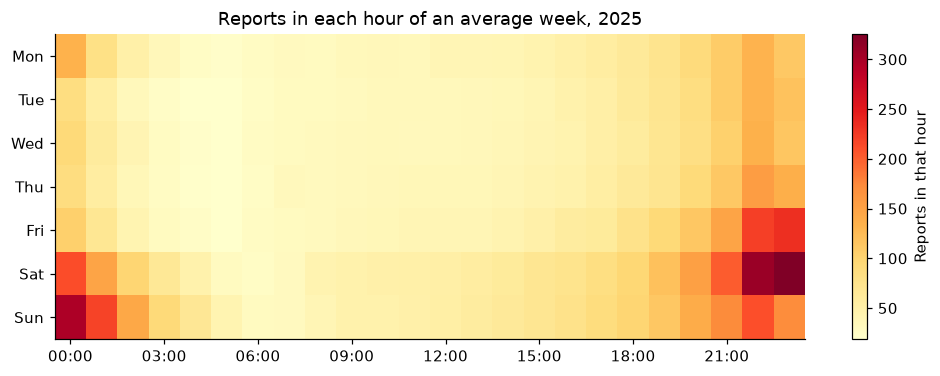

In [3]:
WD = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
order = [f'{d} {h:02d}:00' for d in WD for h in range(24)]
week = r.groupby('how').per_week.sum().reindex(order)
print(f"Reports in an average week: {week.sum():,.0f}")
print(f"Busiest hour: {week.idxmax()} ({week.max():.0f}); quietest: {week.idxmin()} ({week.min():.0f}); {week.max() / week.min():.0f} times")
hour = r.time.str[:2].astype(int)
print(f"Between 10 pm and 7 am: {((hour >= 22) | (hour < 7)).mean():.1%} of reports")
grid = week.values.reshape(7, 24)
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(grid, cmap='YlOrRd', aspect='auto'); ax.set_yticks(range(7), WD); ax.set_xticks(range(0, 24, 3), [f'{h:02d}:00' for h in range(0, 24, 3)])
plt.colorbar(im, label='Reports in that hour'); ax.set_title('Reports in each hour of an average week, 2025'); plt.show()

## 3. By complaint type

In [4]:
t = r.groupby('type').agg(reports=('request', 'size'), a_week=('per_week', 'sum')).sort_values('reports', ascending=False)
t['busiest_hour'] = r.groupby(['type', 'how']).per_week.sum().unstack().idxmax(axis=1)
t.round(1)

,reports,a_week,busiest_hour
type,,,
Noise - Residential,298017,5718.4,Sat 23:00
Noise - Street/Sidewalk,150312,2885.2,Sat 22:00
Noise - Commercial,54957,1054.8,Sat 23:00
Noise,40799,782.3,Sat 08:00
Noise - Vehicle,38808,744.6,Fri 23:00
Noise - Helicopter,18119,347.5,Sun 17:00
Noise - Park,8558,164.3,Sat 22:00
Noise - House of Worship,2085,40.0,Sun 10:00


## 4. Spikes and quiet days

Each day against the median of the same weekday in the three weeks either side. Holidays stand out; they are kept.

In [5]:
days = pd.read_csv(f'{DATA}/tables/days.csv')
days.sort_values('ratio', ascending=False).head(5), days.sort_values('ratio').head(5)

(           date  reports   usual  ratio
 145  2025-05-26     3327  1488.5  2.235
 0    2025-01-01     2003   903.0  2.218
 243  2025-09-01     3078  1534.5  2.006
 184  2025-07-04     2859  1826.0  1.566
 126  2025-05-07     1721  1149.0  1.498,
            date  reports   usual  ratio
 100  2025-04-11     1063  1833.5  0.580
 141  2025-05-22     1017  1678.5  0.606
 101  2025-04-12     1437  2317.0  0.620
 133  2025-05-14     1044  1608.0  0.649
 140  2025-05-21     1128  1693.0  0.666)

## 5. The hexagons

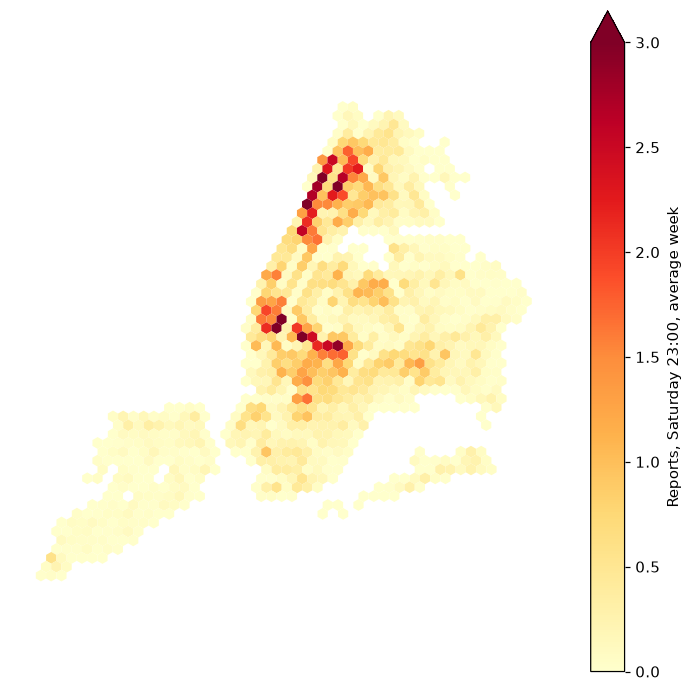

959 hexagons, 1 km across; 11737 reports a week in them


In [6]:
hx = pd.read_csv(f'{DATA}/tables/hexagons_by_hour.csv')
g = gpd.read_file(f'{DATA}/geometry/hexagons.geojson')
sat = g.merge(hx[hx.hour_of_week == 'Sat 23:00'], on='key')
ax = sat.to_crs(2263).plot(column='reports_a_week', cmap='YlOrRd', legend=True, figsize=(8, 8), vmax=3, legend_kwds={'label': 'Reports, Saturday 23:00, average week'})
ax.set_axis_off(); plt.show()
print(len(g), 'hexagons, 1 km across;', round(hx.groupby('hour_of_week').reports_a_week.sum().sum()), 'reports a week in them')

## 6. Community districts

In [7]:
cd = pd.read_csv(f'{DATA}/tables/community_districts.csv')
d = cd[cd.cd % 100 <= 18]
print(len(d), 'districts; busiest hour on Friday night, Saturday or early Sunday in', d.busiest_hour.str.match(r'^(Fri 2|Sat|Sun 0)').sum())
d.sort_values('night_share', ascending=False).head(8)

59 districts; busiest hour on Friday night, Saturday or early Sunday in 57


,cd,district,borough,reports_a_week,reports_2025,night_share,busiest_hour,busiest_hour_reports
58,411,Queens 11,Queens,59.6,3108,57.2,Sun 00:00,2.5
52,405,Queens 5,Queens,172.7,8997,56.8,Sat 23:00,7.8
2,103,Manhattan 3,Manhattan,336.1,17511,56.0,Sat 23:00,11.5
31,304,Brooklyn 4,Brooklyn,310.4,16172,55.9,Sat 23:00,12.4
54,407,Queens 7,Queens,182.5,9512,54.1,Sun 00:00,6.8
50,403,Queens 3,Queens,191.1,9957,53.5,Sat 23:00,6.8
49,402,Queens 2,Queens,134.9,7028,53.5,Sat 23:00,4.7
28,301,Brooklyn 1,Brooklyn,377.7,19680,52.5,Sat 23:00,15.8


## Read it carefully

- **Who reports, not how loud.** How often people report depends on who lives and works somewhere and how they feel
  about calling. A place with few reports is not necessarily quiet.
- **Positions** are where the report says (an address or an intersection), not where the noise was heard.
- **Times** are New York clock time, as 311 records them.